
<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h2>تمرین پنجم کدی یادگیری ماشین</h2>

<p>
در این تمرین از دیتاست <span dir="ltr">Cryotherapy</span> استفاده شده. هدف اینه که نتیجه درمان با استفاده از مدل‌های درخت تصمیم و مدل‌های تجمیعی پیش‌بینی بشه. ستون هدف در این دیتاست <span dir="ltr">Result_of_Treatment</span> است و بقیه ستون‌ها به عنوان ویژگی‌های ورودی استفاده میشن.
</p>

<p>
در بخش اول، مدل <span dir="ltr">DecisionTreeClassifier</span> با چند مقدار مختلف برای <span dir="ltr">max_depth</span> آموزش داده شده و معیارهای <span dir="ltr">Accuracy</span> و <span dir="ltr">F1 Score</span> روی داده تست گزارش شدن. سپس بهترین مقدار <span dir="ltr">max_depth</span> بر اساس <span dir="ltr">F1 Score</span> انتخاب شده، اهمیت ویژگی‌ها بررسی شده و درخت تصمیم رسم شده.
</p>

<p>
در بخش دوم، سه مدل <span dir="ltr">Decision Tree</span>، <span dir="ltr">Random Forest</span> و <span dir="ltr">AdaBoost</span> روی همان تقسیم داده آموزش داده شدن. برای هر مدل زمان آموزش، <span dir="ltr">Accuracy</span> و <span dir="ltr">F1 Score</span> محاسبه شده و در پایان اثر تعداد <span dir="ltr">n_estimators</span> روی دقت مدل‌های تجمیعی بررسی شده.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۱. خواندن داده و پیش‌پردازش</h3>

<p>
ابتدا فایل <span dir="ltr">Cryotherapy.xlsx</span> خوانده میشه و ساختار داده بررسی میشه. چون صورت تمرین گفته برای هر دو بخش پیش‌پردازش مناسب انجام بشه، قبل از آموزش مدل‌ها مقدارهای خالی، ردیف‌های تکراری و نوع ستون‌ها بررسی شدن.
</p>

<p>
در این دیتاست ستون‌های <span dir="ltr">sex</span> و <span dir="ltr">Type</span> ماهیت دسته‌ای دارن، پس برای اینکه مدل‌ها این ستون‌ها رو به شکل عدد ترتیبی تفسیر نکنن، با <span dir="ltr">One-Hot Encoding</span> تبدیل شدن. ستون‌های عددی هم با میانه پر میشن، هرچند در این داده مقدار خالی وجود نداره. سپس داده‌ها با نسبت <span dir="ltr">80/20</span> و به صورت <span dir="ltr">stratified</span> به آموزش و تست تقسیم شدن تا نسبت دو کلاس در هر دو بخش نزدیک به هم بمونه.
</p>

</div>


In [1]:

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_PATH = "Cryotherapy.xlsx"
TARGET_COLUMN = "Result_of_Treatment"
RANDOM_STATE = 24
TEST_SIZE = 0.20

def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

data = pd.read_excel(DATA_PATH, sheet_name="CrayoDataset")

print("Original data shape:", data.shape)
print("Missing values:", int(data.isna().sum().sum()))
print("Duplicate rows:", int(data.duplicated().sum()))

data = data.drop_duplicates().reset_index(drop=True)

print("Data shape after removing duplicates:", data.shape)
print("Target distribution:")
print(data[TARGET_COLUMN].value_counts().sort_index())

display(data.head())

X = data.drop(columns=[TARGET_COLUMN])
y = data[TARGET_COLUMN]

categorical_features = ["sex", "Type"]
numeric_features = [col for col in X.columns if col not in categorical_features]

numeric_transformer = SimpleImputer(strategy="median")
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", make_one_hot_encoder())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    verbose_feature_names_out=False
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train target ratio:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("Test target ratio:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Original data shape: (90, 7)
Missing values: 0
Duplicate rows: 1
Data shape after removing duplicates: (89, 7)
Target distribution:
Result_of_Treatment
0    41
1    48
Name: count, dtype: int64


,sex,age,Time,Number_of_Warts,Type,Area,Result_of_Treatment
0,1,35,12.00,5,1,100,0
1,1,29,7.00,5,1,96,1
2,1,50,8.00,1,3,132,0
3,1,32,11.75,7,3,750,0
4,1,67,9.25,1,1,42,0


Train shape: (71, 6)
Test shape: (18, 6)
Train target ratio:
Result_of_Treatment
0    0.465
1    0.535
Name: proportion, dtype: float64
Test target ratio:
Result_of_Treatment
0    0.444
1    0.556
Name: proportion, dtype: float64



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
خروجی بالا نشون میده داده اصلی ۹۰ ردیف داشته و یک ردیف تکراری از آن حذف شده، پس مدل‌ها روی ۸۹ نمونه نهایی آموزش داده شدن. مقدار خالی در داده وجود نداشته، ولی مرحله پر کردن مقدارهای خالی در <span dir="ltr">Pipeline</span> نگه داشته شده تا پیش‌پردازش کامل و امن باشه.
</p>

<p>
تقسیم داده با نسبت <span dir="ltr">80/20</span> انجام شده و چون از <span dir="ltr">stratify</span> استفاده شده، نسبت کلاس‌های صفر و یک در داده آموزش و تست نزدیک به هم باقی مونده. این موضوع برای محاسبه معیارهایی مثل <span dir="ltr">Accuracy</span> و <span dir="ltr">F1 Score</span> مهمه، چون نتیجه تست به توزیع کلاس‌ها خیلی وابسته میشه.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۲. بخش اول: بررسی عمق درخت تصمیم</h3>

<p>
در این بخش مدل <span dir="ltr">DecisionTreeClassifier</span> برای مقدارهای مختلف <span dir="ltr">max_depth</span> آموزش داده شده. هدف اینه که ببینیم محدود کردن عمق درخت چه اثری روی عملکرد مدل داره. برای هر مقدار عمق، مدل روی داده آموزش برازش شده و سپس <span dir="ltr">Accuracy</span> و <span dir="ltr">F1 Score</span> روی داده تست محاسبه شده.
</p>

<p>
از آنجایی که صورت تمرین گفته بهترین مقدار <span dir="ltr">max_depth</span> بر اساس <span dir="ltr">F1 Score</span> گزارش بشه، بعد از محاسبه نتایج، ردیفی که بیشترین <span dir="ltr">F1 Score</span> داشته به عنوان بهترین مدل این بخش انتخاب شده.
</p>

</div>


,max_depth,Train Accuracy,Test Accuracy,F1 Score
0,2,0.9437,0.9444,0.9474
1,4,0.9718,0.8333,0.8571
2,6,1.0000,0.8889,0.9000
3,8,1.0000,0.8889,0.9000
4,None,1.0000,0.8889,0.9000


Best max_depth based on F1 Score: 2
Best F1 Score: 0.9474


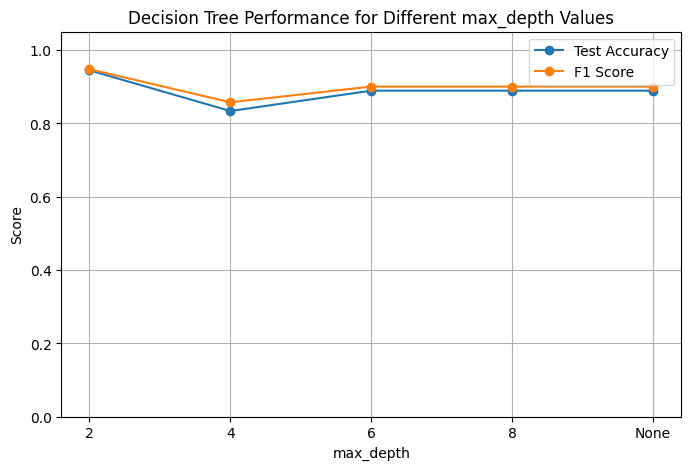

In [2]:

depth_values = [2, 4, 6, 8, None]
depth_rows = []
depth_models = {}

for depth in depth_values:
    tree_pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    ])

    tree_pipeline.fit(X_train, y_train)
    y_pred = tree_pipeline.predict(X_test)

    depth_label = "None" if depth is None else depth
    depth_rows.append({
        "max_depth": depth_label,
        "Train Accuracy": accuracy_score(y_train, tree_pipeline.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })
    depth_models[depth_label] = tree_pipeline

depth_results = pd.DataFrame(depth_rows)
display(depth_results.round(4))

best_row = depth_results.sort_values(["F1 Score", "Test Accuracy"], ascending=False).iloc[0]
best_depth = None if best_row["max_depth"] == "None" else int(best_row["max_depth"])
best_tree_pipeline = depth_models[best_row["max_depth"]]

print("Best max_depth based on F1 Score:", best_row["max_depth"])
print("Best F1 Score:", round(best_row["F1 Score"], 4))

plt.figure(figsize=(8, 5))
plt.plot(depth_results["max_depth"].astype(str), depth_results["Test Accuracy"], marker="o", label="Test Accuracy")
plt.plot(depth_results["max_depth"].astype(str), depth_results["F1 Score"], marker="o", label="F1 Score")
plt.xlabel("max_depth")
plt.ylabel("Score")
plt.title("Decision Tree Performance for Different max_depth Values")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
طبق جدول بالا، بهترین مقدار <span dir="ltr">max_depth</span> بر اساس <span dir="ltr">F1 Score</span> برابر با <span dir="ltr">2</span> شده. در این اجرا، درخت کم‌عمق‌تر عملکرد بهتری روی داده تست داشته، در حالی که درخت‌های عمیق‌تر روی داده آموزش بهتر میشن اما روی داده تست افت می‌کنن.
</p>

<p>
این رفتار نشون میده زیاد کردن عمق درخت لزوما باعث بهتر شدن مدل نمی‌شه. وقتی عمق زیاد میشه، مدل می‌تونه جزئیات بیشتری از داده آموزش رو حفظ کنه، ولی چون دیتاست کوچک است، این کار احتمال بیش‌برازش رو بالا می‌بره. به همین دلیل مدل با عمق کمتر، ساده‌تر و قابل تعمیم‌تر بوده.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۳. اهمیت ویژگی‌ها و رسم درخت تصمیم</h3>

<p>
بعد از انتخاب بهترین مقدار <span dir="ltr">max_depth</span>، اهمیت ویژگی‌ها با استفاده از مدل درخت تصمیم محاسبه شده. چون ستون‌های دسته‌ای با <span dir="ltr">One-Hot Encoding</span> تبدیل شدن، اهمیت ویژگی‌ها برای ستون‌های تبدیل‌شده نمایش داده میشه.
</p>

<p>
در ادامه خود درخت تصمیم هم رسم شده تا مشخص بشه مدل با چه شرط‌هایی نمونه‌ها رو به کلاس‌های مختلف تقسیم کرده.
</p>

</div>


,Feature,Importance
1,Time,0.6546
0,age,0.3454
2,Number_of_Warts,0.0000
3,Area,0.0000
4,sex_1,0.0000
5,sex_2,0.0000
6,Type_1,0.0000
7,Type_2,0.0000
8,Type_3,0.0000


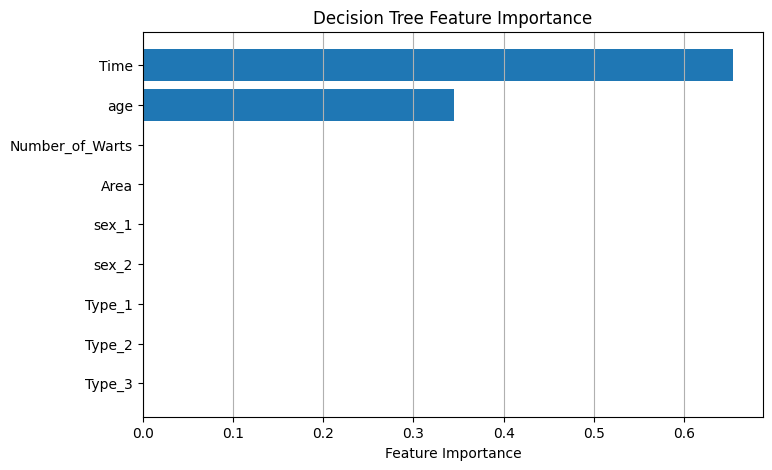

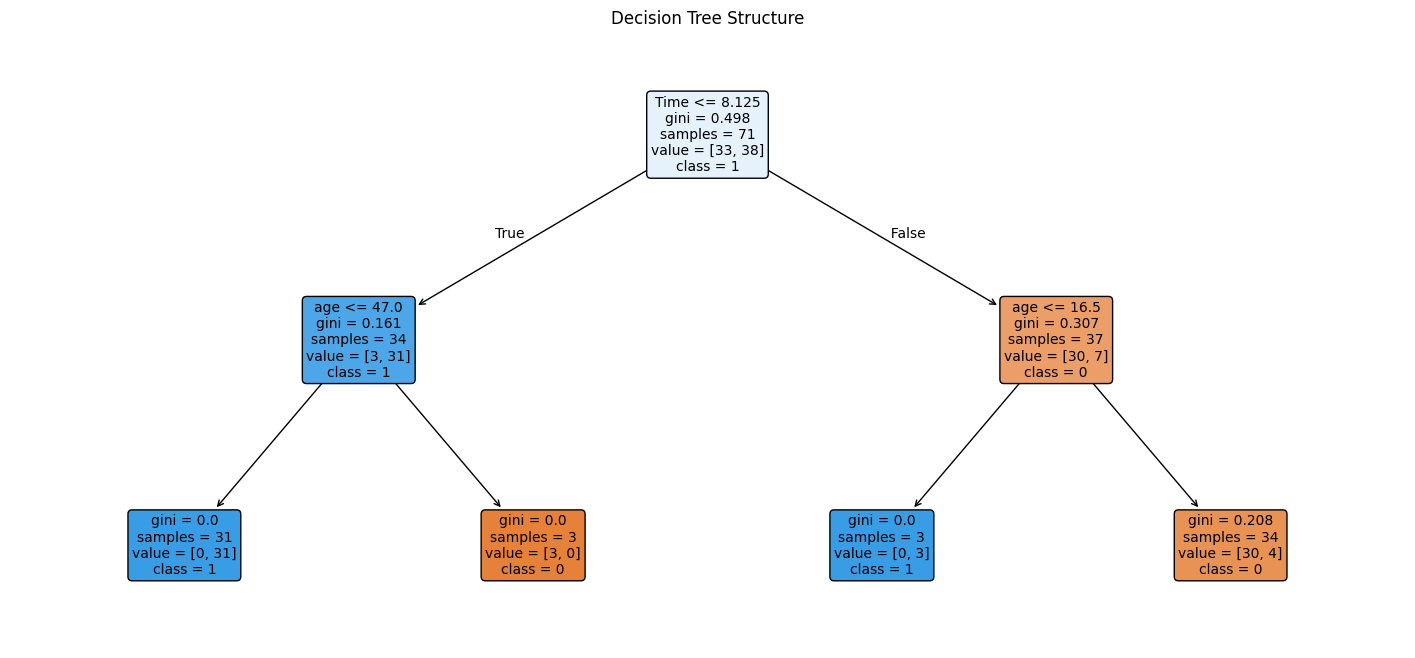

In [3]:

feature_names = best_tree_pipeline.named_steps["preprocess"].get_feature_names_out()
best_tree_model = best_tree_pipeline.named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.round(4))

plt.figure(figsize=(8, 5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Decision Tree Feature Importance")
plt.grid(axis="x")
plt.show()

plt.figure(figsize=(18, 8))
plot_tree(
    best_tree_model,
    feature_names=feature_names,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure")
plt.show()



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
اهمیت ویژگی‌ها نشون میده در این درخت، دو ویژگی <span dir="ltr">Time</span> و <span dir="ltr">age</span> بیشترین نقش رو در تصمیم‌گیری مدل داشتن. مقدارهای اهمیت بقیه ویژگی‌ها در این مدل صفر شده، یعنی درخت انتخاب‌شده برای رسیدن به خروجی نهایی از آن‌ها استفاده نکرده.
</p>

<p>
این نتیجه به معنی بی‌فایده بودن کامل بقیه ویژگی‌ها نیست؛ فقط نشون میده در این تقسیم خاص از داده و با عمق انتخاب‌شده، مدل توانسته با همین چند شرط اصلی تصمیم‌گیری کنه. اگر عمق درخت یا تقسیم داده تغییر کنه، ممکنه ویژگی‌های دیگری هم وارد ساختار درخت بشن.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۴. بخش دوم: مقایسه مدل‌های Decision Tree و Ensemble</h3>

<p>
در این بخش سه مدل <span dir="ltr">Decision Tree</span>، <span dir="ltr">Random Forest</span> و <span dir="ltr">AdaBoost</span> روی همان داده‌های آموزش و تست بخش قبل اجرا شدن. برای مقایسه منصفانه، تقسیم داده و پیش‌پردازش برای همه مدل‌ها یکسان نگه داشته شده.
</p>

<p>
برای هر مدل، زمان آموزش با <span dir="ltr">time.perf_counter</span> اندازه‌گیری شده و سپس معیارهای <span dir="ltr">Accuracy</span> و <span dir="ltr">F1 Score</span> روی داده تست محاسبه شدن. نتیجه نهایی در یک <span dir="ltr">DataFrame</span> نمایش داده شده.
</p>

</div>


In [4]:

models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=best_depth, random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

ensemble_rows = []
trained_models = {}

for model_name, model in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])

    start_time = time.perf_counter()
    model_pipeline.fit(X_train, y_train)
    training_time = time.perf_counter() - start_time

    y_pred = model_pipeline.predict(X_test)

    ensemble_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "Training Time (s)": training_time
    })
    trained_models[model_name] = model_pipeline

ensemble_results = pd.DataFrame(ensemble_rows)
display(ensemble_results.round(4))


,Model,Accuracy,F1 Score,Training Time (s)
0,Decision Tree,0.9444,0.9474,0.0078
1,Random Forest,0.8889,0.9000,0.0720
2,AdaBoost,0.9444,0.9524,0.0770



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
طبق جدول بالا، هر سه مدل روی داده تست عملکرد قابل قبولی داشتن، اما تفاوت‌هایی بین آن‌ها دیده میشه. در این اجرا، <span dir="ltr">Decision Tree</span> و <span dir="ltr">AdaBoost</span> نتیجه نزدیک‌تری به هم داشتن و <span dir="ltr">AdaBoost</span> از نظر <span dir="ltr">F1 Score</span> کمی بهتر عمل کرده. <span dir="ltr">Random Forest</span> هم عملکرد خوبی داشته، ولی روی این تقسیم خاص کمی پایین‌تر از دو مدل دیگر بوده.
</p>

<p>
از نظر زمان آموزش، مدل درخت تصمیم ساده سریع‌تره، چون فقط یک درخت ساخته میشه. مدل‌های <span dir="ltr">Random Forest</span> و <span dir="ltr">AdaBoost</span> زمان بیشتری نیاز دارن، چون چندین مدل پایه آموزش میدن. البته با توجه به کوچک بودن دیتاست، اختلاف زمان‌ها خیلی بزرگ نیست.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۵. نمودار تغییر Accuracy برحسب n_estimators</h3>

<p>
برای بررسی اثر تعداد مدل‌های پایه، مقدار <span dir="ltr">n_estimators</span> برای <span dir="ltr">Random Forest</span> و <span dir="ltr">AdaBoost</span> تغییر داده شده و دقت هر مدل روی داده تست محاسبه شده. این بخش نشان میده افزایش تعداد تخمین‌گرها همیشه به معنی بهتر شدن دقت نیست، مخصوصا وقتی دیتاست کوچک باشه.
</p>

</div>


,Model,n_estimators,Accuracy
0,Random Forest,5,0.8333
1,AdaBoost,5,0.8333
2,Random Forest,10,0.8889
3,AdaBoost,10,0.8889
4,Random Forest,20,0.8333
5,AdaBoost,20,0.8889
6,Random Forest,50,0.8889
7,AdaBoost,50,0.8889
8,Random Forest,100,0.8889
9,AdaBoost,100,0.9444


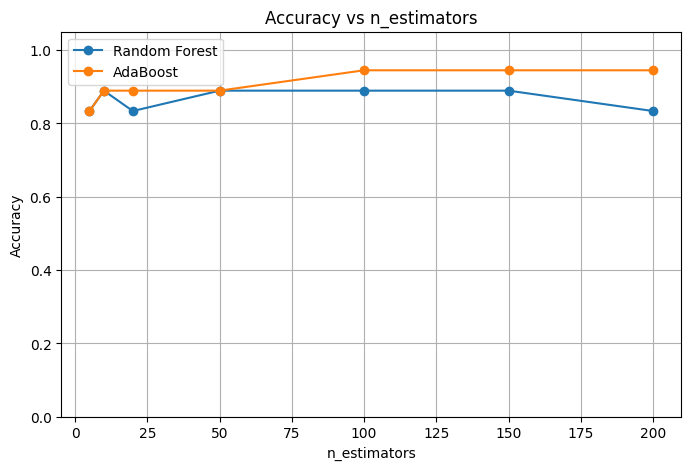

In [5]:

n_estimators_values = [5, 10, 20, 50, 100, 150, 200]
estimator_rows = []

for n_estimators in n_estimators_values:
    estimator_models = {
        "Random Forest": RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=best_depth,
            random_state=RANDOM_STATE
        ),
        "AdaBoost": AdaBoostClassifier(
            n_estimators=n_estimators,
            random_state=RANDOM_STATE
        )
    }

    for model_name, model in estimator_models.items():
        model_pipeline = Pipeline(steps=[
            ("preprocess", preprocessor),
            ("model", model)
        ])
        model_pipeline.fit(X_train, y_train)
        y_pred = model_pipeline.predict(X_test)

        estimator_rows.append({
            "Model": model_name,
            "n_estimators": n_estimators,
            "Accuracy": accuracy_score(y_test, y_pred)
        })

estimator_results = pd.DataFrame(estimator_rows)
display(estimator_results.round(4))

plt.figure(figsize=(8, 5))
for model_name in estimator_results["Model"].unique():
    subset = estimator_results[estimator_results["Model"] == model_name]
    plt.plot(subset["n_estimators"], subset["Accuracy"], marker="o", label=model_name)

plt.xlabel("n_estimators")
plt.ylabel("Accuracy")
plt.title("Accuracy vs n_estimators")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<p>
نمودار بالا نشان میده تغییر مقدار <span dir="ltr">n_estimators</span> روی دقت مدل‌ها اثر دارد، اما این اثر همیشه یکنواخت نیست. در <span dir="ltr">Random Forest</span>، افزایش تعداد درخت‌ها لزوما دقت را بهتر نکرده و در بعضی مقدارها دقت ثابت یا حتی کمتر شده. دلیل اصلی اینه که دیتاست کوچک است و داده تست فقط تعداد کمی نمونه دارد، پس تغییر پیش‌بینی چند نمونه می‌تونه دقت را محسوس تغییر بده.
</p>

<p>
در مدل <span dir="ltr">AdaBoost</span>، با افزایش تعداد تخمین‌گرها عملکرد بهتر شده و بعد از یک مقدار مشخص تقریبا ثابت مانده. این یعنی مدل با تعداد خیلی کم تخمین‌گر هنوز به اندازه کافی یاد نگرفته، ولی بعد از افزایش تعداد مدل‌های پایه، عملکرد پایدارتر شده. با این حال، چون دیتاست کوچک است، نمی‌توان فقط با یک تقسیم داده نتیجه قطعی گرفت.
</p>

</div>



<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۶. جمع‌بندی</h3>

<p>
در این تمرین، ابتدا داده‌ها پیش‌پردازش شدن و سپس مدل <span dir="ltr">Decision Tree</span> برای چند مقدار مختلف <span dir="ltr">max_depth</span> بررسی شد. بهترین مقدار عمق بر اساس <span dir="ltr">F1 Score</span> انتخاب شد و بعد از آن اهمیت ویژگی‌ها و ساختار درخت تصمیم نمایش داده شد.
</p>

<p>
در بخش دوم، مدل‌های <span dir="ltr">Decision Tree</span>، <span dir="ltr">Random Forest</span> و <span dir="ltr">AdaBoost</span> با همان داده‌های آموزش و تست مقایسه شدن. نتایج نشان داد مدل‌های تجمیعی می‌تونن عملکرد خوبی داشته باشن، ولی روی این دیتاست کوچک همیشه برتری واضحی نسبت به درخت تصمیم ساده ندارن.
</p>

<p>
همچنین بررسی <span dir="ltr">n_estimators</span> نشان داد افزایش تعداد مدل‌های پایه همیشه باعث افزایش دقت نمیشه. انتخاب این مقدار باید با توجه به داده، معیار ارزیابی و احتمال بیش‌برازش انجام بشه.
</p>

</div>
